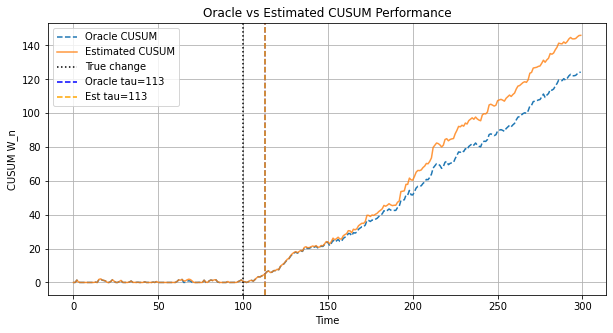

True change point: 100
Oracle detection at: 113
Estimated detection at: 113


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

# --- LLR Estimator as before ---
class LikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None
        self.n_p = None

    def _build_kernels(self, X_p, X_q):
        self.X_p = X_p
        self.n_p = X_p.shape[0]
        gamma = 1.0 / (2 * self.sigma**2)
        K_pp = rbf_kernel(X_p, X_p, gamma=gamma)
        K_qp = rbf_kernel(X_q, X_p, gamma=gamma)
        return K_pp, K_qp

    def _loss_and_grad(self, alpha, K_pp, K_qp):
        g_q = K_qp @ alpha
        g_p = K_pp @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        fit_q = np.mean(g_q)
        fit_p = -np.mean(np.log(g_p))
        reg   = (self.lambda_reg / 2) * (alpha @ (K_pp @ alpha))
        loss = fit_q + fit_p + reg
        grad_fit_q = np.mean(K_qp, axis=0)
        grad_fit_p = -(K_pp @ (1.0 / g_p)) / self.n_p
        grad_reg   = self.lambda_reg * (K_pp @ alpha)
        grad = grad_fit_q + grad_fit_p + grad_reg
        return loss, grad

    def fit(self, X_p, X_q):
        K_pp, K_qp = self._build_kernels(X_p, X_q)
        alpha0 = np.ones(self.n_p) / self.n_p
        bounds = [(0, None)] * self.n_p
        result = minimize(
            fun=lambda a: self._loss_and_grad(a, K_pp, K_qp),
            x0=alpha0, method='L-BFGS-B', jac=True,
            bounds=bounds, options={'maxiter': 1000, 'ftol': 1e-9}
        )
        if not result.success:
            msg = result.message.decode() if isinstance(result.message, bytes) else result.message
            raise RuntimeError("Optimization failed: " + msg)
        self.alpha = result.x

    def predict(self, X):
        if self.alpha is None:
            raise ValueError("Estimator not fitted yet.")
        gamma = 1.0 / (2 * self.sigma**2)
        K_xp = rbf_kernel(X, self.X_p, gamma=gamma)
        return K_xp @ self.alpha

    def predict_log(self, X):
        g_x = self.predict(X)
        return np.log(np.clip(g_x, 1e-8, None))


# --- Estimated CUSUM (uses inverted LLR) ---
class CUSUMEstimated:
    def __init__(self, llr_func, threshold):
        self.llr_func = llr_func
        self.threshold = threshold

    def run(self, X_stream):
        n = X_stream.shape[0]
        W = np.zeros(n)
        tau = None
        for i in range(n):
            # invert to get log(f1/f0)
            log_llr = - self.llr_func(X_stream[i:i+1])[0]
            W[i] = max(0, W[i-1] + log_llr) if i > 0 else max(0, log_llr)
            if tau is None and W[i] >= self.threshold:
                tau = i
        return W, tau


# --- Oracle CUSUM (knows true f0, f1) ---
class CUSUMOracle:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0_pdf = f0_pdf
        self.f1_pdf = f1_pdf
        self.threshold = threshold

    def run(self, X_stream):
        n = X_stream.shape[0]
        W = np.zeros(n)
        tau = None
        for i in range(n):
            x = X_stream[i,0]
            log_llr = np.log(self.f1_pdf(x) / self.f0_pdf(x))
            W[i] = max(0, W[i-1] + log_llr) if i > 0 else max(0, log_llr)
            if tau is None and W[i] >= self.threshold:
                tau = i
        return W, tau


# --- Helper: Gaussian PDF ---
def gaussian_pdf(x, mu, sigma):
    return (1.0 / np.sqrt(2*np.pi*sigma**2)) * np.exp(-0.5 * ((x-mu)/sigma)**2)


# --- Simulation and Comparison ---
if __name__ == "__main__":
    np.random.seed(5)
    # True distributions
    mu0, mu1, sigma0, sigma1 = 0.0, 1.0, 1.0, 1.0

    # 1) Training data
    n_train = 300
    X_p = np.random.normal(mu0, sigma0, (n_train,1))  # f0
    X_q = np.random.normal(mu1, sigma1, (n_train,1))  # f1

    # 2) Fit estimator
    lr_est = LikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
    lr_est.fit(X_p, X_q)

    # 3) Build detectors
    thresh = 5.0
    det_est = CUSUMEstimated(llr_func=lr_est.predict_log, threshold=thresh)
    det_oracle = CUSUMOracle(
        f0_pdf=lambda x: gaussian_pdf(x, mu0, sigma0),
        f1_pdf=lambda x: gaussian_pdf(x, mu1, sigma1),
        threshold=thresh
    )

    # 4) Simulate stream with change at cp
    n_stream = 300
    cp = 100
    stream = np.vstack([
        np.random.normal(mu0, sigma0, (cp,1)),
        np.random.normal(mu1, sigma1, (n_stream-cp,1))
    ])

    # 5) Run both detectors
    W_est, tau_est = det_est.run(stream)
    W_or, tau_or = det_oracle.run(stream)

    # 6) Plot comparison
    plt.figure(figsize=(10,5))
    plt.plot(W_or, label='Oracle CUSUM', linestyle='--')
    plt.plot(W_est, label='Estimated CUSUM', alpha=0.8)
    plt.axvline(cp, color='black', linestyle=':', label='True change')
    plt.axvline(tau_or, color='blue', linestyle='--', label=f'Oracle tau={tau_or}')
    plt.axvline(tau_est, color='orange', linestyle='--', label=f'Est tau={tau_est}')
    plt.legend()
    plt.xlabel('Time')
    plt.ylabel('CUSUM W_n')
    plt.title('Oracle vs Estimated CUSUM Performance')
    plt.grid(True)
    plt.show()

    # 7) Print detection times
    print(f"True change point: {cp}")
    print(f"Oracle detection at: {tau_or}")
    print(f"Estimated detection at: {tau_est}")



Detection Times & Delays Over 10 Seeds:
 seed  tau_oracle  tau_estimated  delay_oracle  delay_est
    0         106            106             6          6
    1         107            107             7          7
    2         119            117            19         17
    3         109            110             9         10
    4         100            100             0          0
    5         113            113            13         13
    6         118            120            18         20
    7         107            106             7          6
    8          15             15           -85        -85
    9         112            114            12         14

Average detection delay (oracle):   0.60
Average detection delay (estimated): 0.80


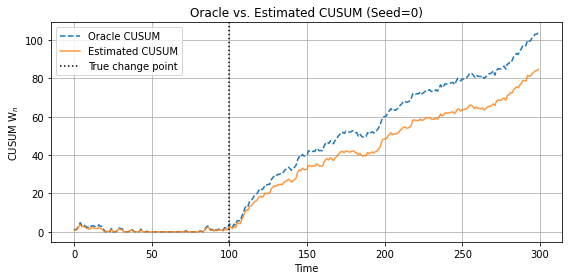

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

# --- Likelihood Ratio Estimator ---
class LikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None
        self.n_p = None

    def _build_kernels(self, X_p, X_q):
        self.X_p = X_p
        self.n_p = X_p.shape[0]
        gamma = 1.0 / (2 * self.sigma**2)
        K_pp = rbf_kernel(X_p, X_p, gamma=gamma)
        K_qp = rbf_kernel(X_q, X_p, gamma=gamma)
        return K_pp, K_qp

    def _loss_and_grad(self, alpha, K_pp, K_qp):
        g_q = K_qp @ alpha
        g_p = K_pp @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        fit_q = np.mean(g_q)
        fit_p = -np.mean(np.log(g_p))
        reg   = 0.5 * self.lambda_reg * (alpha @ (K_pp @ alpha))
        loss = fit_q + fit_p + reg

        grad_fit_q = np.mean(K_qp, axis=0)
        grad_fit_p = -(K_pp @ (1.0 / g_p)) / self.n_p
        grad_reg   = self.lambda_reg * (K_pp @ alpha)
        grad = grad_fit_q + grad_fit_p + grad_reg

        return loss, grad

    def fit(self, X_p, X_q):
        K_pp, K_qp = self._build_kernels(X_p, X_q)
        alpha0 = np.ones(self.n_p) / self.n_p
        bounds = [(0, None)] * self.n_p

        result = minimize(
            fun=lambda a: self._loss_and_grad(a, K_pp, K_qp),
            x0=alpha0,
            method='L-BFGS-B',
            jac=True,
            bounds=bounds,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        if not result.success:
            msg = result.message
            if isinstance(msg, bytes):
                msg = msg.decode()
            raise RuntimeError("Optimization failed: " + msg)

        self.alpha = result.x

    def predict(self, X):
        if self.alpha is None:
            raise ValueError("Estimator not fitted yet.")
        gamma = 1.0 / (2 * self.sigma**2)
        K_xp = rbf_kernel(X, self.X_p, gamma=gamma)
        return K_xp @ self.alpha

    def predict_log(self, X):
        g_x = self.predict(X)
        return np.log(np.clip(g_x, 1e-8, None))


# --- CUSUM using estimated LLR (inverted) ---
class CUSUMEstimated:
    def __init__(self, llr_func, threshold):
        self.llr_func = llr_func
        self.threshold = threshold

    def run(self, X_stream):
        n = X_stream.shape[0]
        W = np.zeros(n)
        tau = None
        for i in range(n):
            # invert because estimator learned f0/f1
            log_llr = - self.llr_func(X_stream[i:i+1])[0]
            W[i] = max(0, W[i-1] + log_llr) if i > 0 else max(0, log_llr)
            if tau is None and W[i] >= self.threshold:
                tau = i
        return W, tau


# --- Oracle CUSUM with true PDFs ---
class CUSUMOracle:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0_pdf = f0_pdf
        self.f1_pdf = f1_pdf
        self.threshold = threshold

    def run(self, X_stream):
        n = X_stream.shape[0]
        W = np.zeros(n)
        tau = None
        for i in range(n):
            x = X_stream[i, 0]
            log_llr = np.log(self.f1_pdf(x) / self.f0_pdf(x))
            W[i] = max(0, W[i-1] + log_llr) if i > 0 else max(0, log_llr)
            if tau is None and W[i] >= self.threshold:
                tau = i
        return W, tau


def gaussian_pdf(x, mu, sigma):
    return (1.0 / np.sqrt(2*np.pi*sigma**2)) * np.exp(-0.5 * ((x-mu)/sigma)**2)


# --- Main experiment: compare oracle vs estimated over 10 seeds ---
if __name__ == "__main__":
    mu0, mu1, sigma0, sigma1 = 0.0, 1.0, 1.0, 1.0
    n_train = 300
    n_stream = 300
    cp = 100
    threshold = 5.0

    records = []
    for seed in range(10):
        np.random.seed(seed)
        # Training data
        X_p = np.random.normal(mu0, sigma0, (n_train,1))  # pre-change
        X_q = np.random.normal(mu1, sigma1, (n_train,1))  # post-change

        # Train estimator
        lr_est = LikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
        lr_est.fit(X_p, X_q)

        # Initialize detectors
        det_est = CUSUMEstimated(llr_func=lr_est.predict_log, threshold=threshold)
        det_or  = CUSUMOracle(
            f0_pdf=lambda x: gaussian_pdf(x, mu0, sigma0),
            f1_pdf=lambda x: gaussian_pdf(x, mu1, sigma1),
            threshold=threshold
        )

        # Simulate stream
        stream = np.vstack([
            np.random.normal(mu0, sigma0, (cp,1)),
            np.random.normal(mu1, sigma1, (n_stream-cp,1))
        ])

        # Run detectors
        _, tau_est = det_est.run(stream)
        _, tau_or  = det_or.run(stream)

        records.append({
            'seed': seed,
            'tau_oracle': tau_or,
            'tau_estimated': tau_est,
            'delay_oracle': None if tau_or is None else tau_or - cp,
            'delay_est':    None if tau_est is None else tau_est - cp
        })

    # Build DataFrame
    df = pd.DataFrame(records)
    print("\nDetection Times & Delays Over 10 Seeds:")
    print(df.to_string(index=False))

    # Compute averages (ignoring None)
    avg_or = df['delay_oracle'].dropna().mean()
    avg_est = df['delay_est'].dropna().mean()
    print(f"\nAverage detection delay (oracle):   {avg_or:.2f}")
    print(f"Average detection delay (estimated): {avg_est:.2f}")

    # Plot one representative run (e.g. seed=0)
    np.random.seed(0)
    stream0 = np.vstack([
        np.random.normal(mu0, sigma0, (cp,1)),
        np.random.normal(mu1, sigma1, (n_stream-cp,1))
    ])
    W_or, _ = CUSUMOracle(lambda x: gaussian_pdf(x, mu0, sigma0),
                          lambda x: gaussian_pdf(x, mu1, sigma1),
                          threshold).run(stream0)
    W_est, _ = CUSUMEstimated(llr_func=lr_est.predict_log, threshold=threshold).run(stream0)

    plt.figure(figsize=(8,4))
    plt.plot(W_or, '--', label='Oracle CUSUM')
    plt.plot(W_est, '-',  label='Estimated CUSUM', alpha=0.8)
    plt.axvline(cp, color='black', linestyle=':', label='True change point')
    plt.xlabel('Time')
    plt.ylabel('CUSUM W$_n$')
    plt.title('Oracle vs. Estimated CUSUM (Seed=0)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
